# SAIA 3113 AI Engineering Topic 3 Lab
## UTM Library Services Assistant — V1 Data Pipeline

This notebook implements **Pathway A: document ingestion** for the project established in Weeks 1–2.

- **S02 Handbook 2026/2027** is the primary policy authority. Its image-based snapshot is routed through official HTML5 metadata inspection and scoped page OCR.
- **S17 FAQ 2025 Compilation** is a text-extractable supplementary source. It never overrides S02 or a newer applicable official notice.
- Both branches preserve source identity, page locators, hashes and processing metadata.
- Prepared records remain **K2 candidates** until authority, applicability and rendered-page checks are complete.

Flow: **select → ingest → inspect/route → prepare → validate → record lineage → repeatability evidence**.


### Run order and expected outputs

1. Run all cells from top to bottom in a fresh Colab runtime.
2. Upload `UTM Library Handbook 2026-2027.pdf` and `UTM Library FAQs 2025 Compilation.pdf` when prompted.
3. The notebook creates the inventory, prepared JSONL files, branch manifests, combined manifest, failure register, decisions and pipeline diagram under `/content/week3_project/`.
4. If the runtime restarts, rerun from the workspace cell.
5. Keep raw snapshots and extracted source text private unless redistribution permission is confirmed.

The Topic 3 dummy dataset is optional; this notebook uses the approved project sources directly. HTML5 inspection and OCR are document loaders within Pathway A, not a mixed pathway.

Public repository copy: upload-widget output and representative source-text samples are intentionally cleared; rerun in Colab to reproduce them.


# **Part A — Select, Inspect and Route the Data**


In [1]:
# Cell 1 — Initialise the Colab workspace
from pathlib import Path

BASE_DIR = Path("/content/week3_project")
RAW_DIR = BASE_DIR / "data" / "raw"
PROCESSED_DIR = BASE_DIR / "data" / "processed"
DOCS_DIR = BASE_DIR / "docs"
PIPE_DIR = BASE_DIR / "data" / "pipeline_v1"

for folder in (RAW_DIR, PROCESSED_DIR, DOCS_DIR, PIPE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Compatibility aliases used by the lab guide.
RAW, PROCESSED, BASE, OUT = RAW_DIR, PROCESSED_DIR, BASE_DIR, PROCESSED_DIR


def project_relative(path):
    """Return a portable POSIX path relative to the project root."""
    return Path(path).resolve().relative_to(BASE_DIR.resolve()).as_posix()


print("Workspace ready:", BASE_DIR)


Workspace ready: /content/week3_project


In [2]:
# Cell 2 — Upload the two approved project source snapshots
# Skip this cell only when the files already exist under RAW_DIR.
from google.colab import files

uploaded = files.upload()
for uploaded_name, uploaded_bytes in uploaded.items():
    target = RAW_DIR / Path(uploaded_name).name
    target.write_bytes(uploaded_bytes)
    print("Saved:", target, "bytes:", target.stat().st_size)


In [3]:
# Cell 3 — REQUIRED: Confirm uploaded inputs recursively
input_files = sorted(path for path in RAW_DIR.rglob("*") if path.is_file())

print("Input count:", len(input_files))
for path in input_files:
    print(path.relative_to(RAW_DIR), "bytes:", path.stat().st_size)

assert input_files, "Upload at least one approved source file before proceeding."
print("Upload verified. The next cell selects the intended files explicitly.")


Input count: 2
UTM Library FAQs 2025 Compilation.pdf bytes: 4792165
UTM Library Handbook 2026-2027.pdf bytes: 52789517
Upload verified. The next cell selects the intended files explicitly.


In [4]:
# Cell 4 — Install and record the Pathway A dependencies
%pip -q install pypdf pymupdf pytesseract Pillow matplotlib requests

import importlib.metadata as metadata
from pypdf import PdfReader

PACKAGE_VERSIONS = {
    name: metadata.version(name)
    for name in ("pypdf", "PyMuPDF", "pytesseract", "Pillow", "matplotlib", "requests")
}
print("Dependencies ready:", PACKAGE_VERSIONS)


Dependencies ready: {'pypdf': '7.0.0', 'PyMuPDF': '2.1', 'pytesseract': '0.3.13', 'Pillow': '11.3.0', 'matplotlib': '3.10.0', 'requests': '2.32.4'}


In [5]:
# Cell 5 — Define source identity, authority and access metadata
PROJECT_SOURCES = [
    {
        "source_id": "S02",
        "filename": "UTM Library Handbook 2026-2027.pdf",
        "title": "UTM Library Handbook 2026/2027",
        "original_url": "https://online.fliphtml5.com/rljlh/UTM-Library-Handbook-2026_digital/",
        "version": "2026/2027 edition",
        "owner": "UTM Library",
        "representation": "Image-based PDF snapshot exported from the official HTML5 flipbook",
        "role": "Primary authority for edition-specific policy",
        "requirement_ids": ["FR1", "FR2", "FR3", "NFR4", "RAI1", "RAI4"],
        "access_rights": "Publicly viewable official source; redistribution permission not verified",
        "capture_date": "2026-11-01",
    },
    {
        "source_id": "S17",
        "filename": "UTM Library FAQs 2025 Compilation.pdf",
        "title": "UTM Library FAQs 2025 Compilation",
        "original_url": "https://library.utm.my/libfaq/2025_compilation/",
        "version": "2025 compilation; snapshot checked in 2026",
        "owner": "UTM Library",
        "representation": "Tagged, text-based PDF snapshot from an officially linked online reader",
        "role": "Supplementary question set; policy statements require authority checking",
        "requirement_ids": ["FR1", "FR2", "FR3", "NFR4", "RAI1", "RAI4"],
        "access_rights": "Publicly viewable official source; redistribution permission not verified",
        "capture_date": "2026-11-01",
    },
]

SOURCE_BY_ID = {source["source_id"]: source for source in PROJECT_SOURCES}

for source in PROJECT_SOURCES:
    path = RAW_DIR / source["filename"]
    status = "FOUND" if path.is_file() else "MISSING"
    print(source["source_id"], status, "-", source["filename"])


S02 FOUND - UTM Library Handbook 2026-2027.pdf
S17 FOUND - UTM Library FAQs 2025 Compilation.pdf


In [6]:
# Cell 6 — REQUIRED: Inspect both selected sources
import hashlib


def sha256_file(path):
    path = Path(path)
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def inspect_pdf_source(path):
    reader = PdfReader(str(path))
    page_texts = [page.extract_text() or "" for page in reader.pages]
    extractable_pages = sum(bool(text.strip()) for text in page_texts)
    characters = sum(len(text) for text in page_texts)
    sample = next((" ".join(text.split())[:400] for text in page_texts if text.strip()), "")
    return {
        "pages": len(reader.pages),
        "extractable_pages": extractable_pages,
        "characters": characters,
        "sample": sample,
        "sha256": sha256_file(path),
        "bytes": path.stat().st_size,
    }


SOURCE_INSPECTIONS = {}
for source in PROJECT_SOURCES:
    path = RAW_DIR / source["filename"]
    if not path.is_file():
        SOURCE_INSPECTIONS[source["source_id"]] = {
            "status": "Missing from Colab raw folder",
            "limitation": "Upload the file and rerun this cell.",
        }
        print("\nMISSING:", source["filename"])
        continue

    inspection = inspect_pdf_source(path)
    if inspection["characters"] == 0:
        status = "Readable file, but no extractable text"
        limitation = (
            "Image-based snapshot of an HTML5 flipbook. Ordinary PDF extraction is insufficient; "
            "use a justified HTML5 extraction or OCR workflow with manual page/table verification."
        )
    else:
        status = "Readable and text-extractable"
        limitation = "Snapshot content must still be checked against source authority, version and applicability."

    SOURCE_INSPECTIONS[source["source_id"]] = {
        **inspection,
        "status": status,
        "limitation": limitation,
    }

    print("\n---", source["source_id"], source["title"], "---")
    print("Pages:", inspection["pages"])
    print("Extractable pages:", inspection["extractable_pages"])
    print("Extracted characters:", inspection["characters"])
    print("Status:", status)
    print("Sample:", repr(inspection["sample"][:300]))
    print("Limitation:", limitation)

assert SOURCE_INSPECTIONS.get("S17", {}).get("characters", 0) > 0, (
    "The executable source S17 must contain extractable text. "
    "Check that the correct FAQ compilation PDF was uploaded."
)


In [7]:
# Cell 7 — Route S02 and initialise the explicit failure-point register
from datetime import datetime, timezone
from html import unescape
import hashlib
import json
import re

HANDBOOK_SOURCE = SOURCE_BY_ID["S02"]
HANDBOOK_PDF = RAW_DIR / HANDBOOK_SOURCE["filename"]
if not HANDBOOK_PDF.is_file():
    raise FileNotFoundError(f"Source file not found: {HANDBOOK_PDF}")

HANDBOOK_URL = HANDBOOK_SOURCE["original_url"]
HANDBOOK_CONFIG_URL = HANDBOOK_URL.rstrip("/") + "/javascript/config.js"
HANDBOOK_PIPE_DIR = PIPE_DIR / "handbook_html5_ocr"
HANDBOOK_INTERIM_DIR = HANDBOOK_PIPE_DIR / "interim"
HANDBOOK_PIPE_DIR.mkdir(parents=True, exist_ok=True)
HANDBOOK_INTERIM_DIR.mkdir(parents=True, exist_ok=True)

FAILURE_POINTS = [
    {
        "id": "FP-01",
        "stage": "INSPECT / ROUTE",
        "condition": "Native PDF extraction returns zero usable characters or zero extractable pages.",
        "detector": "native_character_count == 0 or native_extractable_pages == 0",
        "response": "Do not chunk empty text; route S02 to official HTML5 metadata acquisition plus page OCR.",
        "observed_status": "PENDING",
    },
    {
        "id": "FP-02",
        "stage": "OCR QUALITY GATE",
        "condition": "A selected OCR page fails the minimum text-length or alphanumeric-ratio screen.",
        "detector": "character_count < 120 or alnum_ratio < 0.45",
        "response": "Place affected page records in the manual review queue; keep all S02 records blocked from answering.",
        "observed_status": "PENDING",
    },
]


def write_failure_register():
    lines = [
        "# Week 3 Failure-Point Register", "",
        "| ID | Pipeline stage | Detectable condition | Response | Observed status |",
        "|---|---|---|---|---|",
    ]
    for item in FAILURE_POINTS:
        values = [item["id"], item["stage"], item["condition"], item["response"], item["observed_status"]]
        lines.append("| " + " | ".join(str(value).replace("|", "/") for value in values) + " |")
    path = DOCS_DIR / "week3_failure_register.md"
    path.write_text("\n".join(lines) + "\n", encoding="utf-8")
    return path


native_reader = PdfReader(str(HANDBOOK_PDF))
native_page_text = [page.extract_text() or "" for page in native_reader.pages]
native_character_count = sum(len(text.strip()) for text in native_page_text)
native_extractable_pages = sum(bool(text.strip()) for text in native_page_text)

FAILURE_POINTS[0]["observed_status"] = (
    "TRIGGERED — 0 extractable pages / 0 usable characters"
    if native_character_count == 0 or native_extractable_pages == 0
    else "NOT TRIGGERED"
)
failure_register_path = write_failure_register()
print("S02 native extraction:", native_extractable_pages, "pages;", native_character_count, "characters")
print("FP-01:", FAILURE_POINTS[0]["observed_status"])


S02 native extraction: 0 pages; 0 characters
FP-01: TRIGGERED — 0 extractable pages / 0 usable characters


In [8]:
# Cell 8 — Audit the official HTML5 publication metadata and page alignment
import requests


def flatten_fliphtml5_outline(nodes, parent_caption=""):
    flattened = []
    for node in nodes or []:
        caption = unescape(str(node.get("caption", ""))).strip()
        item = {
            "page": int(node.get("page", 0) or 0),
            "level": int(node.get("level", 0) or 0),
            "caption": caption,
            "parent_caption": parent_caption,
        }
        flattened.append(item)
        flattened.extend(flatten_fliphtml5_outline(node.get("children", []), caption))
    return flattened


viewer_response = requests.get(HANDBOOK_URL, timeout=45)
viewer_response.raise_for_status()
config_response = requests.get(HANDBOOK_CONFIG_URL, timeout=45)
config_response.raise_for_status()
config_match = re.search(r"var\s+htmlConfig\s*=\s*(\{.*\})\s*;?\s*$", config_response.text, flags=re.DOTALL)
if not config_match:
    raise ValueError("The public FlipHTML5 config.js format changed; stop and review acquisition.")

html5_config = json.loads(config_match.group(1))
html5_meta = html5_config.get("meta", {})
html5_outline = flatten_fliphtml5_outline(html5_config.get("ols", []))
html5_page_count = int(html5_meta.get("pageCount", 0) or 0)
assert html5_page_count == len(native_reader.pages), "HTML5 and snapshot page counts differ."

outline_by_page_preview = {}
for item in html5_outline:
    if item["page"] > 0 and item["caption"]:
        outline_by_page_preview.setdefault(item["page"], []).append(item["caption"])
anchor_pages = [13, 17, 24, 35, 52]
anchor_alignment = {str(page): outline_by_page_preview.get(page, [])[:5] for page in anchor_pages}
assert sum(bool(value) for value in anchor_alignment.values()) >= 3, "Too few outline anchors align with the snapshot."

acquisition_audit = {
    "source_id": "S02",
    "authority_url": HANDBOOK_URL,
    "config_url": HANDBOOK_CONFIG_URL,
    "fetched_at_utc": datetime.now(timezone.utc).isoformat(),
    "viewer_http_status": viewer_response.status_code,
    "config_http_status": config_response.status_code,
    "html5_title": html5_meta.get("title"),
    "html5_page_count": html5_page_count,
    "outline_entries": len(html5_outline),
    "outline_pages": sorted({item["page"] for item in html5_outline if item["page"] > 0}),
    "anchor_alignment": anchor_alignment,
    "config_sha256": hashlib.sha256(config_response.content).hexdigest(),
    "snapshot_filename": HANDBOOK_PDF.name,
    "snapshot_sha256": sha256_file(HANDBOOK_PDF),
    "snapshot_page_count": len(native_reader.pages),
    "extraction_decision": "Use HTML5 for identity, page count, outline and anchors; use the frozen official-origin snapshot for page OCR.",
}
html5_audit_path = HANDBOOK_PIPE_DIR / "html5_acquisition_audit.json"
html5_audit_path.write_text(json.dumps(acquisition_audit, indent=2, ensure_ascii=False), encoding="utf-8")

print("HTML5 audit PASS:", html5_page_count, "pages;", len(html5_outline), "outline entries")
print("Anchor pages found:", [page for page in anchor_pages if anchor_alignment[str(page)]])
print("Saved:", project_relative(html5_audit_path))


HTML5 audit PASS: 76 pages; 840 outline entries
Anchor pages found: [13, 17, 24, 35, 52]
Saved: data/pipeline_v1/handbook_html5_ocr/html5_acquisition_audit.json


In [9]:
# Cell 9 — Generate the Part A data inventory from observed evidence
inventory_lines = [
    "# Week 3 Data Inventory", "",
    "Project: UTM Library Services Assistant  ",
    f"Generated: {datetime.now(timezone.utc).isoformat()}  ",
    "Selected pathway: Pathway A — document ingestion", "",
    "## Requirement mapping", "",
    "- FR1–FR2: approved undergraduate library-service content and multi-section evidence.",
    "- FR3 and RAI1: source identity plus page/section locators.",
    "- NFR4 and RAI4: versioned, replaceable sources with provenance and applicability controls.", "",
    "## Source inventory", "",
    "| Source | Role | Inspection evidence | Preparation route and status | Access limitation |",
    "|---|---|---|---|---|",
]

for source in PROJECT_SOURCES:
    inspection = SOURCE_INSPECTIONS[source["source_id"]]
    evidence = (
        f"{inspection['pages']} pages; {inspection['extractable_pages']} text pages; "
        f"{inspection['characters']} characters; SHA-256 `{inspection['sha256']}`"
    )
    route = (
        "HTML5 metadata/outline audit + scoped page OCR; K2 candidates require rendered-page review"
        if source["source_id"] == "S02"
        else "Native PDF extraction + page-aware paragraph chunks; K2 supplementary candidates"
    )
    inventory_lines.append(
        f"| {source['source_id']} | {source['role']} | {evidence} | {route} | {source['access_rights']} |"
    )

inventory_lines += [
    "", "## Source precedence", "",
    "S02 is the default authority for edition-specific policy. S17 and current official webpages are supplementary. "
    "S17 never overrides S02 or a newer applicable official notice; unresolved conflicts are held for review.",
    "", "## Implementation decision", "",
    "Both sources are implemented in one Pathway A pipeline. S02 uses a justified HTML5-assisted OCR route because native extraction failed; "
    "S17 uses its text layer. Prepared outputs remain K2 candidates and are not approved knowledge.",
    "", "Raw snapshots and extracted source text remain local unless redistribution permission is confirmed.",
]

inventory_path = DOCS_DIR / "week3_data_inventory.md"
inventory_path.write_text("\n".join(inventory_lines) + "\n", encoding="utf-8")
print("Inventory saved:", project_relative(inventory_path))


Inventory saved: docs/week3_data_inventory.md


# **Part B — Prepare and Validate the Data (Pathway A)**

S17 is used to compare chunking methods. S02 follows the documented HTML5-assisted OCR route. Both outputs retain page-level provenance and remain review candidates.


In [10]:
# Cell 10 — Source selection and common lineage registry
import json


def select_source(relative_path):
    selected = RAW_DIR / relative_path
    if not selected.is_file():
        raise FileNotFoundError(f"Source not found: {selected}")
    return selected


def save_manifest(records):
    manifest = {
        "pipeline_version": "week3-v1.1",
        "generated_at_utc": datetime.now(timezone.utc).isoformat(),
        "knowledge_stage": "K2_candidate",
        "records": records,
    }
    target = BASE_DIR / "data" / "week3_manifest.json"
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")
    return target, manifest


lineage_entries = {}


def register_lineage(source, output, processing, source_id):
    source, output = Path(source).resolve(), Path(output).resolve()
    if not source.is_file():
        raise FileNotFoundError(f"Source file not found: {source}")
    if not output.is_file() or output.stat().st_size == 0:
        raise ValueError(f"Prepared output is missing or empty: {output}")
    source.relative_to(RAW_DIR.resolve())
    output.relative_to(BASE_DIR.resolve())
    if not processing.strip():
        raise ValueError("A processing description is required.")
    lineage_entries[(str(source), str(output))] = {
        "source": source, "output": output, "processing": processing.strip(), "source_id": source_id,
    }


print("Lineage registry ready.")


Lineage registry ready.


In [11]:
# Cell 9 — Pathway A1: Extract, clean and compare chunking approaches
import re
import statistics

FAQ_SOURCE = SOURCE_BY_ID["S17"]
f = select_source(FAQ_SOURCE["filename"])


def extract_pdf_pages(path):
    reader = PdfReader(str(path))
    pages = [
        {"page": page_number, "text": page.extract_text() or ""}
        for page_number, page in enumerate(reader.pages, start=1)
    ]
    if not any(page["text"].strip() for page in pages):
        raise ValueError(
            "No extractable text found. Image-based PDFs require a separate OCR or HTML5 extraction workflow."
        )
    return pages


def clean_extracted_text(text):
    # Conservative cleaning only: normalize non-breaking spaces, horizontal whitespace
    # and excessive blank lines. Do not remove substantive content automatically.
    text = text.replace("\u00a0", " ")
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()


def fixed_chunks(text, size=500):
    if size <= 0:
        raise ValueError("Chunk size must be positive")
    return [text[index:index + size].strip() for index in range(0, len(text), size) if text[index:index + size].strip()]


def paragraph_aware_chunks(text, size=500):
    if size <= 0:
        raise ValueError("Chunk size must be positive")
    blocks = [block.strip() for block in re.split(r"\n\s*\n", text) if block.strip()]
    if len(blocks) <= 1:
        blocks = [line.strip() for line in text.splitlines() if line.strip()]

    chunks = []
    current = ""
    for block in blocks:
        if len(block) > size:
            if current:
                chunks.append(current)
                current = ""
            chunks.extend(fixed_chunks(block, size=size))
        elif len(current) + len(block) + (2 if current else 0) <= size:
            current += ("\n\n" if current else "") + block
        else:
            if current:
                chunks.append(current)
            current = block
    if current:
        chunks.append(current)
    return chunks


def build_page_chunks(pages, method, size=500):
    records = []
    for page in pages:
        clean_text = clean_extracted_text(page["text"])
        if not clean_text:
            continue
        if method == "fixed":
            chunks = fixed_chunks(clean_text, size=size)
        elif method == "paragraph-aware":
            chunks = paragraph_aware_chunks(clean_text, size=size)
        else:
            raise ValueError("Choose 'fixed' or 'paragraph-aware'.")
        for page_chunk_number, chunk in enumerate(chunks, start=1):
            records.append(
                {
                    "page": page["page"],
                    "page_chunk_number": page_chunk_number,
                    "text": chunk,
                }
            )
    return records


def chunk_statistics(records):
    lengths = [len(record["text"]) for record in records]
    return {
        "chunks": len(records),
        "pages_covered": len({record["page"] for record in records}),
        "minimum_length": min(lengths) if lengths else 0,
        "median_length": statistics.median(lengths) if lengths else 0,
        "maximum_length": max(lengths) if lengths else 0,
        "empty_chunks": sum(not record["text"].strip() for record in records),
    }


CHUNK_SIZE = 500
pages = extract_pdf_pages(f)
fixed_candidate = build_page_chunks(pages, method="fixed", size=CHUNK_SIZE)
paragraph_candidate = build_page_chunks(pages, method="paragraph-aware", size=CHUNK_SIZE)

comparison = {
    "fixed": chunk_statistics(fixed_candidate),
    "paragraph-aware": chunk_statistics(paragraph_candidate),
}

print("Source:", f.name)
print("Pages loaded:", len(pages))
print("Extracted characters:", sum(len(page["text"]) for page in pages))
print(json.dumps(comparison, indent=2))

for label, candidate in (("fixed", fixed_candidate), ("paragraph-aware", paragraph_candidate)):
    print(f"\n--- {label} sample ---")
    for sample in candidate[:2]:
        print("Page", sample["page"], "|", repr(sample["text"][:300]))


In [12]:
# Cell 12 — Select the S17 method and export traceable K2 candidate records
CHOSEN_METHOD = "paragraph-aware"
chosen_chunks = paragraph_candidate if CHOSEN_METHOD == "paragraph-aware" else fixed_candidate
source_digest = sha256_file(f)
processing_label = f"page-aware {CHOSEN_METHOD} character chunks; size={CHUNK_SIZE}; overlap=0"

prepared_records = []
for chunk in chosen_chunks:
    prepared_records.append({
        "record_id": f"S17-p{chunk['page']:03d}-c{chunk['page_chunk_number']:03d}",
        "text": chunk["text"],
        "source_id": "S17",
        "source_filename": f.name,
        "source_url": FAQ_SOURCE["original_url"],
        "source_sha256": source_digest,
        "page": chunk["page"],
        "version": FAQ_SOURCE["version"],
        "capture_date": FAQ_SOURCE["capture_date"],
        "processing": processing_label,
        "knowledge_stage": "K2_candidate",
        "approval_status": "pending_authority_applicability_review",
        "approved_for_answering": False,
        "status": "Supplementary candidate; S02/newer official policy takes precedence.",
    })

prepared_path = PROCESSED_DIR / "prepared_text.jsonl"
with prepared_path.open("w", encoding="utf-8") as handle:
    for record in prepared_records:
        handle.write(json.dumps(record, ensure_ascii=False, sort_keys=True) + "\n")

print("S17 method:", CHOSEN_METHOD, "| records:", len(prepared_records), "| bytes:", prepared_path.stat().st_size)


S17 method: paragraph-aware | records: 351 | bytes: 353282


In [13]:
# Cell 13 — Validate the S17 prepared output
required_fields = {
    "record_id", "text", "source_id", "source_filename", "source_url", "source_sha256",
    "page", "version", "processing", "knowledge_stage", "approval_status", "approved_for_answering",
}
assert prepared_path.is_file() and prepared_path.stat().st_size > 0
with prepared_path.open("r", encoding="utf-8") as handle:
    exported_records = [json.loads(line) for line in handle if line.strip()]

record_ids = [record["record_id"] for record in exported_records]
assert exported_records
assert all(required_fields <= set(record) for record in exported_records)
assert all(record["text"].strip() for record in exported_records)
assert all(record["source_sha256"] == source_digest for record in exported_records)
assert len(record_ids) == len(set(record_ids)), "Duplicate S17 record_id found."
assert not any(record["approved_for_answering"] for record in exported_records)

print("S17 output contract PASS | records:", len(exported_records), "| unique IDs:", len(set(record_ids)))


S17 output contract PASS | records: 351 | unique IDs: 351


In [14]:
# Cell 14 — Record Part B S17 lineage
register_lineage(f, prepared_path, processing_label, "S17")

lineage_records = []
for index, entry in enumerate(lineage_entries.values(), start=1):
    source, output = entry["source"], entry["output"]
    metadata = SOURCE_BY_ID[entry["source_id"]]
    lineage_records.append({
        "lineage_id": f"L{index:02d}",
        "source_id": entry["source_id"],
        "source_filename": source.relative_to(RAW_DIR.resolve()).as_posix(),
        "source_url": metadata["original_url"],
        "source_version": metadata["version"],
        "source_sha256": sha256_file(source),
        "prepared_output": output.relative_to(BASE_DIR.resolve()).as_posix(),
        "prepared_sha256": sha256_file(output),
        "processing_note": entry["processing"],
        "knowledge_stage": "K2_candidate",
        "approval_status": "pending_authority_applicability_review",
        "access_rights": metadata["access_rights"],
    })

part_b_manifest_path, part_b_manifest = save_manifest(lineage_records)
print("Part B lineage saved:", project_relative(part_b_manifest_path), "| records:", len(lineage_records))


Part B lineage saved: data/week3_manifest.json | records: 1


In [15]:
# Cell 13 — REQUIRED: Validate the saved Part B lineage manifest
saved_manifest = json.loads(part_b_manifest_path.read_text(encoding="utf-8"))
saved_records = saved_manifest.get("records", [])

assert saved_records, "No lineage records found."
assert len(saved_records) == len(lineage_entries), "Saved lineage count does not match registration."

for record in saved_records:
    source = RAW_DIR / record["source_filename"]
    output = BASE_DIR / record["prepared_output"]
    assert source.is_file(), f"Missing source: {source}"
    assert output.is_file(), f"Missing output: {output}"
    assert sha256_file(source) == record["source_sha256"], f"Source checksum mismatch: {source}"
    assert sha256_file(output) == record["prepared_sha256"], f"Output checksum mismatch: {output}"

print("COMMON LINEAGE VALIDATION: PASS")
print("Verified records:", len(saved_records))
print("Manifest:", part_b_manifest_path)


COMMON LINEAGE VALIDATION: PASS
Verified records: 1
Manifest: /content/week3_project/data/week3_manifest.json


In [16]:
# Cell 16 — Define the justified S02 V1 page scope and OCR environment
import shutil
import subprocess
import sys

if shutil.which("tesseract") is None:
    subprocess.run(["apt-get", "-qq", "update"], check=True)
    subprocess.run(["apt-get", "-qq", "install", "-y", "tesseract-ocr"], check=True)

import pymupdf
import pytesseract

# 13–29: opening hours, rules, membership, loan eligibility, fines and renewal.
# 35: borrowing/returning. 49–52: services, ILL and payment of fines.
HANDBOOK_SCOPE_PAGES = sorted(set(range(13, 30)) | {35} | set(range(49, 53)))
assert min(HANDBOOK_SCOPE_PAGES) >= 1 and max(HANDBOOK_SCOPE_PAGES) <= html5_page_count

OCR_DPI = 200
OCR_CONFIG = "--oem 3 --psm 6"
OCR_ENGINE_VERSION = str(pytesseract.get_tesseract_version()).splitlines()[0]
scope_outline = [item for item in html5_outline if item["page"] in HANDBOOK_SCOPE_PAGES]
scope_summary = {
    "selected_pages": HANDBOOK_SCOPE_PAGES,
    "selected_page_count": len(HANDBOOK_SCOPE_PAGES),
    "selection_basis": "Official HTML5 outline aligned with the Week 2 V1 undergraduate service-policy scope.",
    "requirement_mapping": {
        "FR1": "pages 17–29, 35 and 49–52: membership, borrowing, renewal, fines and services",
        "FR2": "multiple selected policy sections retained with page locators",
        "FR3_RAI1": "every output record preserves source and page provenance",
    },
    "excluded_pages": "Outside the current V1 service-policy scope; deferred, not rejected.",
    "ocr_engine": "Tesseract",
    "ocr_engine_version": OCR_ENGINE_VERSION,
    "ocr_dpi": OCR_DPI,
    "ocr_config": OCR_CONFIG,
    "package_versions": PACKAGE_VERSIONS,
}
scope_path = HANDBOOK_PIPE_DIR / "handbook_v1_scope.json"
scope_path.write_text(json.dumps(scope_summary, indent=2, ensure_ascii=False), encoding="utf-8")
print("S02 scope ready:", len(HANDBOOK_SCOPE_PAGES), "pages | Tesseract", OCR_ENGINE_VERSION)


S02 scope ready: 22 pages | Tesseract 5.3.4


In [17]:
# Cell 17 — OCR the selected S02 pages with page-level provenance
from io import BytesIO
from PIL import Image


def normalise_ocr_text(text):
    rows = [" ".join(row.split()) for row in text.replace("\u00a0", " ").splitlines()]
    return "\n".join(row for row in rows if row).strip()


outline_by_page = {}
for item in html5_outline:
    if item["page"] > 0 and item["caption"]:
        outline_by_page.setdefault(item["page"], []).append(item["caption"])

snapshot_digest = sha256_file(HANDBOOK_PDF)  # Compute once, outside the OCR loop.
ocr_records = []
with pymupdf.open(str(HANDBOOK_PDF)) as handbook_document:
    matrix = pymupdf.Matrix(OCR_DPI / 72, OCR_DPI / 72)
    for page_number in HANDBOOK_SCOPE_PAGES:
        page = handbook_document.load_page(page_number - 1)
        pixmap = page.get_pixmap(matrix=matrix, colorspace=pymupdf.csGRAY, alpha=False)
        image = Image.open(BytesIO(pixmap.tobytes("png")))
        clean_text = normalise_ocr_text(
            pytesseract.image_to_string(image, lang="eng", config=OCR_CONFIG, timeout=120)
        )
        ocr_records.append({
            "source_id": "S02", "page": page_number, "text": clean_text,
            "character_count": len(clean_text), "source_url": HANDBOOK_URL,
            "snapshot_filename": HANDBOOK_PDF.name, "snapshot_sha256": snapshot_digest,
            "html5_config_sha256": acquisition_audit["config_sha256"],
            "html5_outline_anchors": outline_by_page.get(page_number, []),
            "ocr_engine": "Tesseract", "ocr_engine_version": OCR_ENGINE_VERSION,
            "ocr_dpi": OCR_DPI, "ocr_config": OCR_CONFIG,
        })
        print(f"OCR p.{page_number:02d}: {len(clean_text):5d} characters")

handbook_ocr_raw_path = HANDBOOK_INTERIM_DIR / "handbook_ocr_raw.jsonl"
with handbook_ocr_raw_path.open("w", encoding="utf-8") as handle:
    for record in ocr_records:
        handle.write(json.dumps(record, ensure_ascii=False, sort_keys=True) + "\n")
assert len(ocr_records) == len(HANDBOOK_SCOPE_PAGES)
print("OCR raw saved:", project_relative(handbook_ocr_raw_path), "| SHA-256:", sha256_file(handbook_ocr_raw_path)[:12])


OCR p.13:  1265 characters
OCR p.14:   322 characters
OCR p.15:  2387 characters
OCR p.16:  1782 characters
OCR p.17:   911 characters
OCR p.18:  2063 characters
OCR p.19:  2006 characters
OCR p.20:  1310 characters
OCR p.21:  1771 characters
OCR p.22:  1319 characters
OCR p.23:  1213 characters
OCR p.24:   437 characters
OCR p.25:   270 characters
OCR p.26:   568 characters
OCR p.27:   689 characters
OCR p.28:  1673 characters
OCR p.29:  1411 characters
OCR p.35:   877 characters
OCR p.49:   165 characters
OCR p.50:  1464 characters
OCR p.51:  1210 characters
OCR p.52:  1699 characters
OCR raw saved: data/pipeline_v1/handbook_html5_ocr/interim/handbook_ocr_raw.jsonl | SHA-256: fe4e31165f4a


In [18]:
# Cell 18 — Quality-gate OCR and create the S02 candidate/review outputs
def token_set(text):
    return set(re.findall(r"[a-z0-9]{4,}", text.lower()))


def handbook_ocr_quality(record):
    text = record["text"]
    anchors = token_set(" ".join(record.get("html5_outline_anchors", [])))
    tokens = token_set(text)
    alnum_ratio = sum(character.isalnum() for character in text) / max(len(text), 1)
    anchor_recall = len(anchors & tokens) / len(anchors) if anchors else None
    screen_pass = len(text) >= 120 and alnum_ratio >= 0.45
    return {
        "non_empty": bool(text.strip()),
        "character_count": len(text),
        "alnum_ratio": round(alnum_ratio, 3),
        "outline_anchor_recall": None if anchor_recall is None else round(anchor_recall, 3),
        "automatic_screen": "PASS" if screen_pass else "REVIEW",
    }


ocr_quality = [{"page": record["page"], **handbook_ocr_quality(record)} for record in ocr_records]
quality_by_page = {row["page"]: row for row in ocr_quality}
failed_screen_pages = [row["page"] for row in ocr_quality if row["automatic_screen"] == "REVIEW"]
FAILURE_POINTS[1]["observed_status"] = (
    "TRIGGERED — manual review queue pages " + ", ".join(map(str, failed_screen_pages))
    if failed_screen_pages else "NOT TRIGGERED — all selected pages passed the minimum automatic screen"
)

candidate_chunks = build_page_chunks(ocr_records, method="paragraph-aware", size=CHUNK_SIZE)
HIGH_RISK_PAGES = set(range(13, 30)) | set(range(49, 53))
handbook_prepared_records = []
for chunk in candidate_chunks:
    page = chunk["page"]
    page_quality = quality_by_page[page]
    handbook_prepared_records.append({
        "record_id": f"S02-p{page:03d}-c{chunk['page_chunk_number']:03d}",
        "text": chunk["text"], "source_id": "S02", "source_filename": HANDBOOK_PDF.name,
        "source_url": HANDBOOK_URL, "source_sha256": snapshot_digest,
        "html5_config_sha256": acquisition_audit["config_sha256"], "page": page,
        "version": HANDBOOK_SOURCE["version"], "capture_date": HANDBOOK_SOURCE["capture_date"],
        "processing": f"HTML5 metadata/outline audit + Tesseract {OCR_ENGINE_VERSION} OCR at {OCR_DPI} dpi + paragraph-aware chunks size={CHUNK_SIZE}",
        "automatic_screen": page_quality["automatic_screen"],
        "manual_review_queue": page in failed_screen_pages,
        "review_priority": "HIGH" if page in HIGH_RISK_PAGES or page in failed_screen_pages else "STANDARD",
        "human_page_check": "REQUIRED",
        "knowledge_stage": "K2_candidate",
        "approval_status": "pending_rendered_page_review",
        "approved_for_answering": False,
        "status": "OCR candidate only; verify against the rendered handbook page before answering.",
    })

required = {
    "record_id", "text", "source_id", "source_url", "source_sha256", "html5_config_sha256",
    "page", "version", "processing", "manual_review_queue", "human_page_check",
    "knowledge_stage", "approval_status", "approved_for_answering",
}
ids = [record["record_id"] for record in handbook_prepared_records]
assert handbook_prepared_records and all(required <= set(record) for record in handbook_prepared_records)
assert all(record["text"].strip() for record in handbook_prepared_records)
assert len(ids) == len(set(ids)), "Duplicate S02 record_id found."
assert not any(record["approved_for_answering"] for record in handbook_prepared_records)

handbook_prepared_path = HANDBOOK_PIPE_DIR / "prepared_handbook_text.jsonl"
review_queue_path = HANDBOOK_PIPE_DIR / "handbook_manual_review_queue.jsonl"
with handbook_prepared_path.open("w", encoding="utf-8") as handle:
    for record in handbook_prepared_records:
        handle.write(json.dumps(record, ensure_ascii=False, sort_keys=True) + "\n")
review_records = [record for record in handbook_prepared_records if record["manual_review_queue"]]
with review_queue_path.open("w", encoding="utf-8") as handle:
    for record in review_records:
        handle.write(json.dumps(record, ensure_ascii=False, sort_keys=True) + "\n")

failure_register_path = write_failure_register()
print("S02 candidates:", len(handbook_prepared_records), "| queue records:", len(review_records))
print("FP-02:", FAILURE_POINTS[1]["observed_status"])


S02 candidates: 67 | queue records: 5
FP-02: TRIGGERED — manual review queue pages 17, 24, 27


# **Part C — Build and Document the V1 Data Pipeline**

Part C packages both document branches, verifies reproducible outputs at the appropriate level, records lineage and generates the final documentation artefacts.


In [19]:
# Cell 19 — Common V1 pipeline utilities
PIPELINE_RUNS = {}


def resolve_source(relative_path):
    source = RAW_DIR / relative_path
    if not source.is_file():
        raise FileNotFoundError(f"Source file not found: {source}")
    return source


def execute_pipeline(kind, source, inspect_fn, prepare_fn, configuration):
    source = Path(source)
    inspection = inspect_fn(source, configuration)
    output_dir = PIPE_DIR / kind
    output_dir.mkdir(parents=True, exist_ok=True)
    outputs, mappings, method = prepare_fn(source, output_dir, configuration)
    outputs = [Path(path) for path in outputs]
    if not outputs or any(not path.is_file() or path.stat().st_size == 0 for path in outputs):
        raise ValueError("One or more prepared outputs are missing or empty.")

    metadata = SOURCE_BY_ID[configuration["source_id"]]
    record = {
        "pipeline_version": "week3-v1.1",
        "generated_at_utc": datetime.now(timezone.utc).isoformat(),
        "data_type": kind,
        "knowledge_stage": "K2_candidate",
        "configuration": configuration,
        "processing_method": method,
        "sources": [{
            "source_id": configuration["source_id"], "path": project_relative(source),
            "url": metadata["original_url"], "version": metadata["version"], "sha256": sha256_file(source),
        }],
        "outputs": [project_relative(path) for path in outputs],
        "source_output_mapping": mappings,
        "inspection": inspection,
        "validation": {
            "output_count": len(outputs),
            "output_sha256": [sha256_file(path) for path in outputs],
            "output_bytes": [path.stat().st_size for path in outputs],
        },
        "access_rights": metadata["access_rights"],
        "known_limitations": [
            "S17 is supplementary and cannot override S02 or a newer applicable official notice.",
            "Prepared records require authority and applicability review before answering use.",
        ],
    }
    manifest_path = output_dir / "pipeline_manifest.json"
    manifest_path.write_text(json.dumps(record, indent=2, ensure_ascii=False), encoding="utf-8")
    return record


def register_and_run(kind, source, inspect_fn, prepare_fn, configuration):
    def runner():
        return execute_pipeline(kind, source, inspect_fn, prepare_fn, configuration)
    first = runner()
    PIPELINE_RUNS[kind] = {"first": first, "runner": runner}
    return first


print("Common Part C utilities ready.")


Common Part C utilities ready.


In [20]:
# Cell 20 — Execute the S17 document branch
DOCUMENT_CONFIG = {
    "source_id": "S17",
    "method": CHOSEN_METHOD,
    "chunk_size": CHUNK_SIZE,
    "overlap": 0,
    "preserve_page_locator": True,
}
DOCUMENT_SOURCE = resolve_source(FAQ_SOURCE["filename"])


def inspect_document(source, configuration):
    extracted_pages = extract_pdf_pages(source)
    characters = sum(len(page["text"]) for page in extracted_pages)
    return {
        "source": source.name,
        "pages": len(extracted_pages),
        "extractable_pages": sum(bool(page["text"].strip()) for page in extracted_pages),
        "characters": characters,
        "source_sha256": sha256_file(source),
    }


def prepare_document(source, output_dir, configuration):
    extracted_pages = extract_pdf_pages(source)
    candidate_chunks = build_page_chunks(
        extracted_pages,
        method=configuration["method"],
        size=configuration["chunk_size"],
    )
    if not candidate_chunks:
        raise ValueError("No document chunks were produced.")

    digest = sha256_file(source)
    method = (
        f"page-aware {configuration['method']} character chunks; "
        f"size={configuration['chunk_size']}; overlap={configuration['overlap']}"
    )
    target = output_dir / "prepared_text.jsonl"
    with target.open("w", encoding="utf-8") as handle:
        for chunk in candidate_chunks:
            record = {
                "record_id": f"S17-p{chunk['page']:03d}-c{chunk['page_chunk_number']:03d}",
                "text": chunk["text"],
                "source_id": "S17",
                "source_filename": source.name,
                "source_url": FAQ_SOURCE["original_url"],
                "source_sha256": digest,
                "page": chunk["page"],
                "version": FAQ_SOURCE["version"],
                "processing": method,
                "knowledge_stage": "K2_candidate",
                "approval_status": "pending_authority_applicability_review",
                "approved_for_answering": False,
                "status": "Supplementary candidate; S02/newer official policy takes precedence.",
            }
            handle.write(json.dumps(record, ensure_ascii=False) + "\n")

    mappings = [{"source": project_relative(source), "output": project_relative(target)}]
    return [target], mappings, method


run_documents = register_and_run(
    "documents",
    DOCUMENT_SOURCE,
    inspect_document,
    prepare_document,
    DOCUMENT_CONFIG,
)

print("S17 branch PASS | outputs:", run_documents["validation"]["output_count"], "| manifest: data/pipeline_v1/documents/pipeline_manifest.json")


S17 branch PASS | outputs: 1 | manifest: data/pipeline_v1/documents/pipeline_manifest.json


In [21]:
# Cell 21 — Verify full rerun repeatability for the S17 branch
assert PIPELINE_RUNS, "Run the selected document pipeline first."
for kind, entry in PIPELINE_RUNS.items():
    first, second = entry["first"], entry["runner"]()
    assert first["sources"] == second["sources"]
    assert first["validation"] == second["validation"]
    assert first["source_output_mapping"] == second["source_output_mapping"]
    print(f"S17 full-rerun repeatability PASS: {kind}")


S17 full-rerun repeatability PASS: documents


In [22]:
# Cell 22 — Record S02 lineage and deterministic post-OCR preparation evidence
def jsonl_payload(records):
    return "".join(json.dumps(record, ensure_ascii=False, sort_keys=True) + "\n" for record in records).encode("utf-8")


saved_payload = handbook_prepared_path.read_bytes()
rebuilt_payload = jsonl_payload(handbook_prepared_records)
saved_sha256 = hashlib.sha256(saved_payload).hexdigest()
rebuilt_sha256 = hashlib.sha256(rebuilt_payload).hexdigest()
assert saved_payload == rebuilt_payload and saved_sha256 == rebuilt_sha256

validation_guards = {
    "non_empty_output": bool(saved_payload),
    "required_schema": all(required <= set(record) for record in handbook_prepared_records),
    "unique_record_ids": len(ids) == len(set(ids)),
    "checksum_reproduced": saved_sha256 == rebuilt_sha256,
}
assert all(validation_guards.values())

handbook_manifest = {
    "pipeline_version": "week3-v1.1",
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "data_type": "documents",
    "pathway": "A — PDF/HTML5 document ingestion with page OCR fallback",
    "knowledge_stage": "K2_candidate",
    "source_priority": "S02 primary authority; S17 supplementary and cannot override S02.",
    "source": {
        "source_id": "S02", "authority_url": HANDBOOK_URL, "version": HANDBOOK_SOURCE["version"],
        "snapshot_path": project_relative(HANDBOOK_PDF), "snapshot_sha256": snapshot_digest,
        "html5_config_url": HANDBOOK_CONFIG_URL, "html5_config_sha256": acquisition_audit["config_sha256"],
    },
    "scope": scope_summary,
    "processing": {
        "html5_role": "identity, page count, outline and OCR anchors",
        "body_text_method": "page OCR from frozen official-origin snapshot",
        "ocr_engine": "Tesseract", "ocr_engine_version": OCR_ENGINE_VERSION,
        "ocr_dpi": OCR_DPI, "ocr_config": OCR_CONFIG,
        "chunking": f"paragraph-aware; size={CHUNK_SIZE}; overlap=0; page boundaries retained",
    },
    "source_output_mapping": [
        {"source": HANDBOOK_URL, "output": project_relative(html5_audit_path)},
        {"source": project_relative(HANDBOOK_PDF), "output": project_relative(handbook_ocr_raw_path)},
        {"source": project_relative(handbook_ocr_raw_path), "output": project_relative(handbook_prepared_path)},
        {"source": project_relative(handbook_prepared_path), "output": project_relative(review_queue_path)},
    ],
    "validation": {
        "selected_pages": len(HANDBOOK_SCOPE_PAGES),
        "ocr_non_empty_pages": sum(row["non_empty"] for row in ocr_quality),
        "automatic_screen_review_pages": failed_screen_pages,
        "candidate_record_count": len(handbook_prepared_records),
        "manual_review_queue_records": len(review_records),
        "prepared_output_bytes": len(saved_payload),
        "prepared_output_sha256": saved_sha256,
        "validation_guards": validation_guards,
        "repeatability_scope": "deterministic post-OCR chunk preparation and JSONL serialization; OCR itself was not rerun",
        "repeatability_sha256": rebuilt_sha256,
        "repeatability_status": "PASS",
        "approved_for_answering": False,
    },
    "failure_points": FAILURE_POINTS,
    "known_limitations": [
        "The public HTML5 configuration is not treated as a complete body-text API.",
        "OCR may alter tables, amounts, durations or eligibility conditions.",
        "Every S02 candidate requires rendered-page review before answering use.",
        "The current V1 scope selects 22 of 76 pages.",
    ],
}
handbook_manifest_path = HANDBOOK_PIPE_DIR / "pipeline_manifest.json"
handbook_manifest_path.write_text(json.dumps(handbook_manifest, indent=2, ensure_ascii=False), encoding="utf-8")

s17_manifest_path = PIPE_DIR / "documents" / "pipeline_manifest.json"
combined_manifest = {
    "pipeline_version": "week3-v1.1",
    "generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "source_policy": {
        "primary": "S02 UTM Library Handbook 2026/2027",
        "supplementary": "S17 UTM Library FAQs 2025 Compilation",
        "conflict_rule": "S17 never overrides S02 or a newer applicable official page/notice.",
    },
    "branches": [
        {"source_id": "S02", "manifest": project_relative(handbook_manifest_path), "manifest_sha256": sha256_file(handbook_manifest_path), "knowledge_stage": "K2_candidate", "answering_status": "BLOCKED pending rendered-page review"},
        {"source_id": "S17", "manifest": project_relative(s17_manifest_path), "manifest_sha256": sha256_file(s17_manifest_path), "knowledge_stage": "K2_candidate", "answering_status": "Supplementary; authority/applicability review required"},
    ],
}
combined_manifest_path = BASE_DIR / "data" / "week3_combined_manifest.json"
combined_manifest_path.write_text(json.dumps(combined_manifest, indent=2, ensure_ascii=False), encoding="utf-8")

print("S02 post-OCR deterministic preparation PASS:", saved_sha256[:12])
print("Combined manifest saved:", project_relative(combined_manifest_path))


S02 post-OCR deterministic preparation PASS: b2c3847b0795
Combined manifest saved: data/week3_combined_manifest.json


In [23]:
# Cell 23 — Generate the integrated pipeline decisions document
fixed_stats, paragraph_stats = comparison["fixed"], comparison["paragraph-aware"]
decision_lines = [
    "# Week 3 Pipeline Decisions", "", "Project: UTM Library Services Assistant", "",
    "## Source and requirement decisions", "",
    "S02 Handbook 2026/2027 is the primary policy authority. S17 FAQ 2025 is supplementary and cannot override S02 or a newer applicable official notice. "
    "Both branches preserve page-level provenance for FR3/RAI1 and replaceable, versioned source records for NFR4/RAI4.", "",
    "S02 native extraction failed (FP-01), so the pipeline uses the official HTML5 publication for identity/page structure and a frozen official-origin snapshot for scoped OCR. "
    "All S02 and S17 outputs remain K2 candidates; they are not approved answering knowledge.", "",
    "## Part B comparison", "",
    "| Method | Chunks | Pages | Median length | Maximum | Empty |", "|---|---:|---:|---:|---:|---:|",
    f"| Fixed-size | {fixed_stats['chunks']} | {fixed_stats['pages_covered']} | {fixed_stats['median_length']} | {fixed_stats['maximum_length']} | {fixed_stats['empty_chunks']} |",
    f"| Paragraph-aware | {paragraph_stats['chunks']} | {paragraph_stats['pages_covered']} | {paragraph_stats['median_length']} | {paragraph_stats['maximum_length']} | {paragraph_stats['empty_chunks']} |", "",
    f"Selected S17 configuration: `{processing_label}`. It better respects observed paragraph/line boundaries while retaining page locators. "
    "It is not semantic chunking and cannot repair PDF reading-order or table errors.", "",
    "## Workflow decisions", "",
    "- Hybrid batch preparation: retain source snapshots, staged outputs and hashes for controlled reprocessing.",
    "- S17 branch: native text extraction, paragraph-aware chunks and a full rerun repeatability check.",
    "- S02 branch: HTML5 audit, selected-page OCR, quality screen, manual review queue and deterministic post-OCR preparation check.",
    "- Current official focused webpages remain deferred supplementary sources for later conflict checking.", "",
    "## Failure points and controls", "",
    "- FP-01: empty native extraction routes S02 to HTML5-assisted OCR.",
    "- FP-02: minimum OCR quality-screen failures enter the manual review queue.",
    "- Separate validation guards enforce non-empty output, required schema, unique IDs and reproducible checksums; these guards passed in this run.", "",
    "## Access and approval caveat", "",
    "A hash proves byte identity, not authority, permission or policy correctness. Raw snapshots and extracted text stay local unless redistribution is permitted. "
    "Tables, amounts, eligibility, duration and campus-specific conditions require rendered-page review before promotion from K2 candidate to approved knowledge.",
]
decisions_path = DOCS_DIR / "week3_pipeline_decisions.md"
decisions_path.write_text("\n".join(decision_lines) + "\n", encoding="utf-8")
print("Decisions saved:", project_relative(decisions_path))


Decisions saved: docs/week3_pipeline_decisions.md


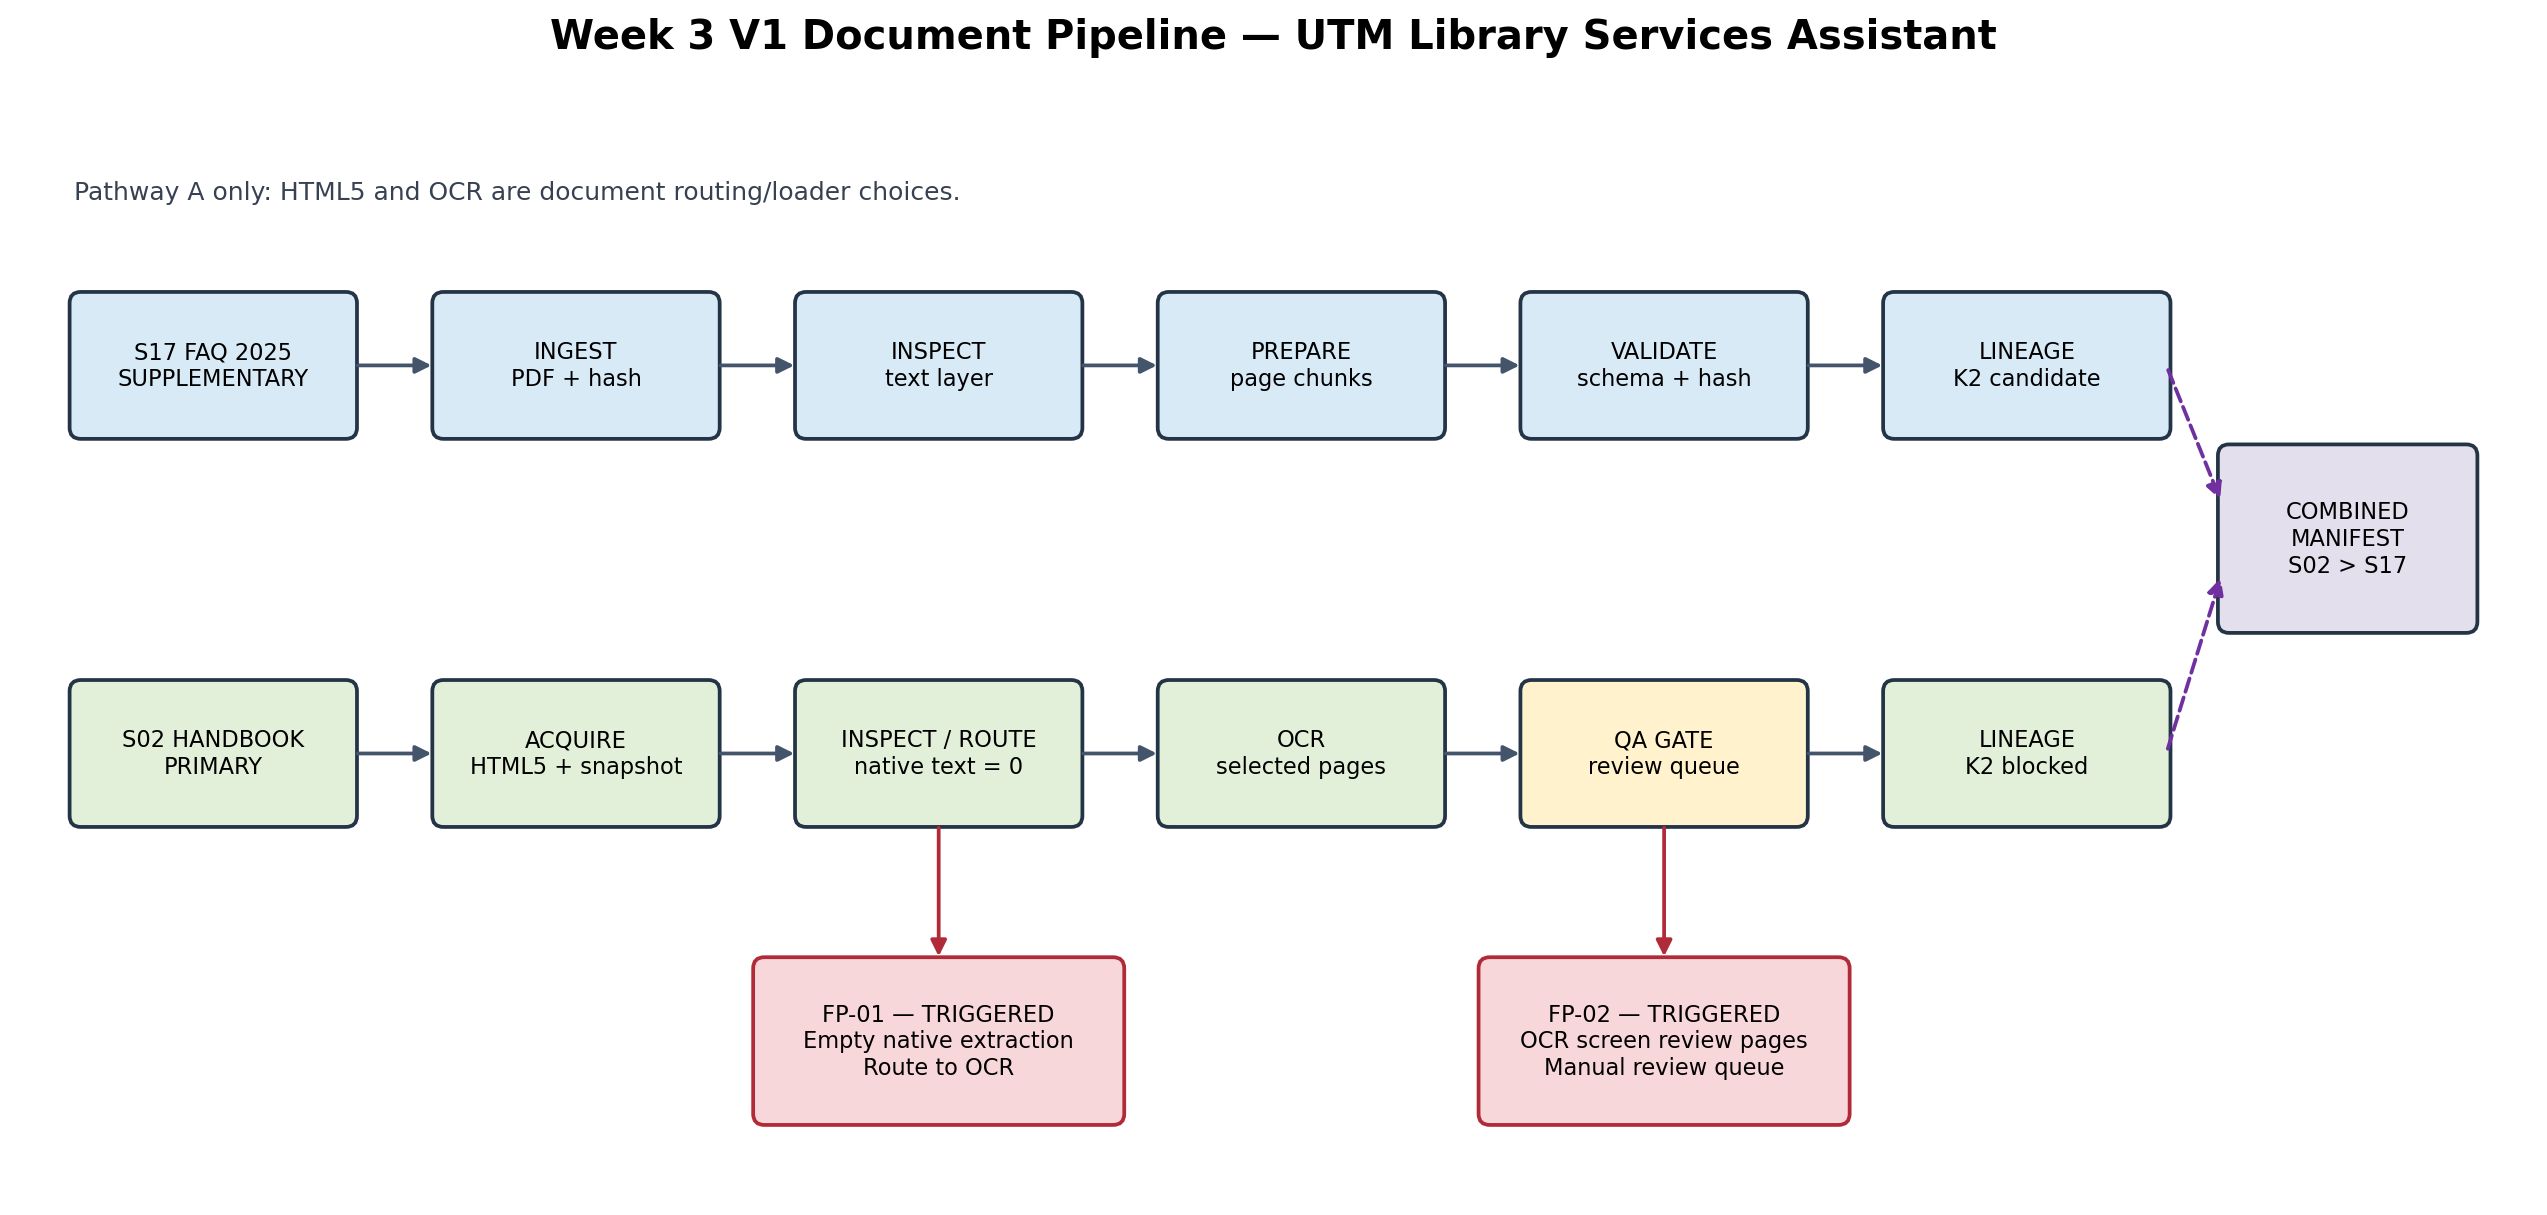

Diagram saved: docs/week3_pipeline_diagram.png


In [24]:
# Cell 24 — Generate the final pipeline diagram with both observed failure points
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from IPython.display import Image as DisplayImage, display


def draw_box(ax, x, y, width, height, text, facecolor, edgecolor="#243447", fontsize=9):
    box = FancyBboxPatch((x, y), width, height, boxstyle="round,pad=0.03,rounding_size=0.08", linewidth=1.5, edgecolor=edgecolor, facecolor=facecolor)
    ax.add_patch(box)
    ax.text(x + width / 2, y + height / 2, text, ha="center", va="center", fontsize=fontsize, wrap=True)


def arrow(ax, start, end, color="#44546a", dashed=False):
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle="-|>", mutation_scale=13, linewidth=1.5, color=color, linestyle="--" if dashed else "-"))


fig, ax = plt.subplots(figsize=(18, 8))
ax.set_xlim(0, 18); ax.set_ylim(0, 8); ax.axis("off")
ax.set_title("Week 3 V1 Document Pipeline — UTM Library Services Assistant", fontsize=16, weight="bold", pad=16)

top = [(0.4, "S17 FAQ 2025\nSUPPLEMENTARY"), (3.0, "INGEST\nPDF + hash"), (5.6, "INSPECT\ntext layer"), (8.2, "PREPARE\npage chunks"), (10.8, "VALIDATE\nschema + hash"), (13.4, "LINEAGE\nK2 candidate")]
bottom = [(0.4, "S02 HANDBOOK\nPRIMARY"), (3.0, "ACQUIRE\nHTML5 + snapshot"), (5.6, "INSPECT / ROUTE\nnative text = 0"), (8.2, "OCR\nselected pages"), (10.8, "QA GATE\nreview queue"), (13.4, "LINEAGE\nK2 blocked")]
for nodes, y, color in ((top, 5.5, "#d9eaf7"), (bottom, 2.7, "#e2f0d9")):
    for index, (x, label) in enumerate(nodes):
        draw_box(ax, x, y, 2.0, 1.0, label, "#fff2cc" if y == 2.7 and index == 4 else color)
        if index:
            arrow(ax, (nodes[index - 1][0] + 2.0, y + 0.5), (x, y + 0.5))

draw_box(ax, 5.3, 0.55, 2.6, 1.15, "FP-01 — TRIGGERED\nEmpty native extraction\nRoute to OCR", "#f8d7da", "#b02a37")
draw_box(ax, 10.5, 0.55, 2.6, 1.15, "FP-02 — TRIGGERED\nOCR screen review pages\nManual review queue", "#f8d7da", "#b02a37")
arrow(ax, (6.6, 2.7), (6.6, 1.7), "#b02a37")
arrow(ax, (11.8, 2.7), (11.8, 1.7), "#b02a37")
draw_box(ax, 15.8, 4.1, 1.8, 1.3, "COMBINED\nMANIFEST\nS02 > S17", "#e4dfec")
arrow(ax, (15.4, 6.0), (15.8, 5.0), "#7030a0", True)
arrow(ax, (15.4, 3.2), (15.8, 4.5), "#7030a0", True)
ax.text(0.4, 7.2, "Pathway A only: HTML5 and OCR are document routing/loader choices.", fontsize=10, color="#374151")

pipeline_diagram_path = DOCS_DIR / "week3_pipeline_diagram.png"
fig.savefig(pipeline_diagram_path, dpi=180, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(DisplayImage(filename=str(pipeline_diagram_path)))
print("Diagram saved:", project_relative(pipeline_diagram_path))


In [25]:
# Cell 25 — Final complete artefact and logic checkpoint
expected_artifacts = [
    inventory_path, prepared_path, part_b_manifest_path,
    PIPE_DIR / "documents" / "prepared_text.jsonl",
    PIPE_DIR / "documents" / "pipeline_manifest.json",
    html5_audit_path, scope_path, handbook_ocr_raw_path,
    handbook_prepared_path, review_queue_path, handbook_manifest_path,
    combined_manifest_path, failure_register_path, decisions_path, pipeline_diagram_path,
]
missing = [path for path in expected_artifacts if not path.is_file() or path.stat().st_size == 0]
assert not missing, f"Missing or empty artefacts: {missing}"

assert {item["id"] for item in FAILURE_POINTS} == {"FP-01", "FP-02"}
assert FAILURE_POINTS[0]["observed_status"].startswith("TRIGGERED")
assert all(validation_guards.values())
assert not any(record["approved_for_answering"] for record in handbook_prepared_records)
assert not any(record["approved_for_answering"] for record in exported_records)

print("FINAL CHECKPOINT PASS")
print("Artefacts:", len(expected_artifacts), "| S17 records:", len(exported_records), "| S02 candidates:", len(handbook_prepared_records))
print("Manual review pages:", failed_screen_pages)
print("Failure points:", {item['id']: item['observed_status'] for item in FAILURE_POINTS})
print("Public-repository reminder: do not commit raw snapshots or extracted source text without permission.")


FINAL CHECKPOINT PASS
Artefacts: 15 | S17 records: 351 | S02 candidates: 67
Manual review pages: [17, 24, 27]
Failure points: {'FP-01': 'TRIGGERED — 0 extractable pages / 0 usable characters', 'FP-02': 'TRIGGERED — manual review queue pages 17, 24, 27'}
Public-repository reminder: do not commit raw snapshots or extracted source text without permission.


In [26]:
# Cell 26 — Package and download the final Week 3 artefacts
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

archive_path = Path("/content/week3_project_artifacts.zip")

if archive_path.exists():
    archive_path.unlink()

included_files = []

with ZipFile(archive_path, "w", compression=ZIP_DEFLATED) as archive:
    for source_path in sorted(BASE_DIR.rglob("*")):
        if not source_path.is_file():
            continue

        relative_path = source_path.relative_to(BASE_DIR)

        # Exclude the original PDFs from the ZIP.
        if relative_path.parts[:2] == ("data", "raw"):
            continue

        archive_name = Path("week3_project") / relative_path
        archive.write(source_path, arcname=archive_name.as_posix())
        included_files.append(relative_path.as_posix())

assert archive_path.is_file()
assert archive_path.stat().st_size > 0
assert included_files

print("ZIP PACKAGE PASS")
print("Included files:", len(included_files))
print("ZIP size:", archive_path.stat().st_size, "bytes")
print("ZIP path:", archive_path)
print("\nPackaged files:")

for item in included_files:
    print("-", item)

print(
    "\nReminder: prepared/OCR text may contain source content. "
    "Keep the ZIP private unless redistribution permission is confirmed."
)

files.download(str(archive_path))

ZIP PACKAGE PASS
Included files: 15
ZIP size: 286861 bytes
ZIP path: /content/week3_project_artifacts.zip

Packaged files:
- data/pipeline_v1/documents/pipeline_manifest.json
- data/pipeline_v1/documents/prepared_text.jsonl
- data/pipeline_v1/handbook_html5_ocr/handbook_manual_review_queue.jsonl
- data/pipeline_v1/handbook_html5_ocr/handbook_v1_scope.json
- data/pipeline_v1/handbook_html5_ocr/html5_acquisition_audit.json
- data/pipeline_v1/handbook_html5_ocr/interim/handbook_ocr_raw.jsonl
- data/pipeline_v1/handbook_html5_ocr/pipeline_manifest.json
- data/pipeline_v1/handbook_html5_ocr/prepared_handbook_text.jsonl
- data/processed/prepared_text.jsonl
- data/week3_combined_manifest.json
- data/week3_manifest.json
- docs/week3_data_inventory.md
- docs/week3_failure_register.md
- docs/week3_pipeline_decisions.md
- docs/week3_pipeline_diagram.png

Reminder: prepared/OCR text may contain source content. Keep the ZIP private unless redistribution permission is confirmed.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>